# DSA4213 Assignment 1: Part III (downstream classification)

**Before you start:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

**Task:** predict each abstract's disease category (5 classes) from representations of the **frozen** language models trained in Parts I and II.

| Representation | Language model | Pooling |
|---|---|---|
| LSTM-Random | `results/part1_lstm` | mean of token states |
| LSTM-Skip-gram | `results/part2_lstm_skipgram` | mean |
| LSTM-GloVe | `results/part2_lstm_glove` | mean |
| Transformer | `results/part1_transformer` | mean |
| LSTM-Random (last) | `results/part1_lstm` | final token state (pooling comparison) |
| LSTM-GloVe-ft | `results/part2_lstm_glove_ft` | mean (only if the optional run exists) |
| TF-IDF (no LM) | none | reference baseline |

The same classifier is used for every representation: standardised features + logistic regression, with C chosen on validation macro-F1.

## 1. Check the GPU (a GPU only speeds up feature extraction; a CPU also works)

In [ ]:
import torch, subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"],
                     capture_output=True, text=True).stdout)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

name, memory.total [MiB]
Tesla T4, 15360 MiB

torch 2.11.0+cu130 | CUDA available: True


## 2. Mount Drive and go to the project folder

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
PROJECT = "/content/drive/MyDrive/DSA4213/dsa4213-individual-assignment"
assert os.path.exists(f"{PROJECT}/src/train.py"), f"Project not found at {PROJECT}"
os.chdir(PROJECT)
print("Working in", os.getcwd()); print(sorted(os.listdir()))

Mounted at /content/drive
Working in /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment
['.git', '.ipynb_checkpoints', 'README.md', 'configs', 'data', 'requirements.txt', 'results', 'results_run1', 'src']


## 3. Check that the Part III files and the Part I/II models are in Drive

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment

import os
needed = ["src/downstream.py", "src/analyze_part3.py", "configs/part3.yaml",
          "data/processed/vocab.json", "data/embeddings/glove_covered.npy"]
for run in ["part1_lstm", "part1_transformer", "part2_lstm_skipgram", "part2_lstm_glove"]:
    needed += [f"results/{run}/best.pt", f"results/{run}/eval.json"]
missing = [p for p in needed if not os.path.exists(p)]
assert not missing, "Missing (copy these into Drive / finish Parts I-II first):\n  " + "\n  ".join(missing)
print("All Part III files and Part I/II models found.")
if os.path.exists("results/part2_lstm_glove_ft/best.pt"):
    print("Optional fine-tuned GloVe run found: it will be included.")

/content
All Part III files and Part I/II models found.


## 4. Extract features and train the classifiers
For each frozen LM:
1. Every abstract is read in 128-token chunks (as in LM training).
2. The top-layer hidden states are pooled into one vector.
3. A logistic regression is trained on the train split, C is picked on validation, and the model is evaluated once on test.

Set `RERUN = True` to recompute everything.

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment

import os
RERUN = False
if os.path.exists("results/part3/results.json") and not RERUN:
    print("results/part3/results.json exists, skipping (set RERUN = True to recompute)")
else:
    !python -m src.downstream --config configs/part3.yaml

/content
Task sizes: {'train': 5946, 'val': 661, 'test': 1691} | test class counts: [443, 141, 225, 408, 474]
LSTM-Random          dim    256  C=1.0    val macro-F1 0.5162  test macro-F1 0.4979  acc 0.5612
LSTM-Skip-gram       dim    256  C=10.0   val macro-F1 0.6403  test macro-F1 0.6358  acc 0.6718
LSTM-GloVe           dim    256  C=10.0   val macro-F1 0.5919  test macro-F1 0.5989  acc 0.6487
Transformer          dim    200  C=0.01   val macro-F1 0.6762  test macro-F1 0.6583  acc 0.6937
LSTM-Random (last)   dim    256  C=1.0    val macro-F1 0.3774  test macro-F1 0.3316  acc 0.4299
skip LSTM-GloVe-ft: /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/results/part2_lstm_glove_ft/best.pt not found
TF-IDF (no LM)       dim  14503  C=10.0   val macro-F1 0.7991  test macro-F1 0.7802  acc 0.7883
wrote /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/results/part3/results.json and predictions.csv


## 5. Analyse: confidence intervals, per-class F1, LM-vs-downstream ranking, error analysis

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment

!python -m src.analyze_part3

/content
    Representation  LM test PPL Test macro-F1 [95% CI]  Test accuracy
       LSTM-Random    92.551591   0.498 [0.472, 0.524]       0.561206
    LSTM-Skip-gram    88.141110   0.636 [0.611, 0.662]       0.671792
        LSTM-GloVe   105.806458   0.599 [0.574, 0.627]       0.648729
       Transformer    90.787928   0.658 [0.633, 0.682]       0.693672
LSTM-Random (last)    92.551591   0.332 [0.310, 0.352]       0.429923
    TF-IDF (no LM)          NaN   0.780 [0.758, 0.801]       0.788291

Best LM representation: Transformer | wrote /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/results/part3/summary.md


## 6. Look at the results

/content


# Part III results: disease-category classification

Single-label abstracts: train 5,946, val 661, test 1,691. Frozen LMs; StandardScaler + logistic regression with C chosen on validation macro-F1 (identical for every representation).

## Main results

| Representation     | Pooling   |   LM test PPL |   Feature dim |     C |   Val macro-F1 |   Test accuracy |   Extraction (s) | Test macro-F1 [95% CI]   |
|:-------------------|:----------|--------------:|--------------:|------:|---------------:|----------------:|-----------------:|:-------------------------|
| LSTM-Random        | mean      |         92.55 |           256 |  1    |         0.5162 |          0.5612 |            5.89  | 0.498 [0.472, 0.524]     |
| LSTM-Skip-gram     | mean      |         88.14 |           256 | 10    |         0.6403 |          0.6718 |            5.086 | 0.636 [0.611, 0.662]     |
| LSTM-GloVe         | mean      |        105.8  |           256 | 10    |         0.5919 |          0.6487 |            5.26  | 0.599 [0.574, 0.627]     |
| Transformer        | mean      |         90.79 |           200 |  0.01 |         0.6762 |          0.6937 |            4.499 | 0.658 [0.633, 0.682]     |
| LSTM-Random (last) | last      |         92.55 |           256 |  1    |         0.3774 |          0.4299 |            6.092 | 0.332 [0.310, 0.352]     |
| TF-IDF (no LM)     | tf-idf    |        nan    |         14503 | 10    |         0.7991 |          0.7883 |          nan     | 0.780 [0.758, 0.801]     |

## Paired bootstrap: macro-F1 difference vs. Transformer

| Representation     | minus       |   macro-F1 difference |   ci_low |   ci_high | ci_excludes_zero   |
|:-------------------|:------------|----------------------:|---------:|----------:|:-------------------|
| LSTM-Random        | Transformer |               -0.1604 |  -0.1889 |   -0.1308 | True               |
| LSTM-Skip-gram     | Transformer |               -0.0225 |  -0.0510 |    0.0033 | False              |
| LSTM-GloVe         | Transformer |               -0.0594 |  -0.0871 |   -0.0308 | True               |
| LSTM-Random (last) | Transformer |               -0.3267 |  -0.3546 |   -0.2952 | True               |
| TF-IDF (no LM)     | Transformer |                0.1219 |   0.0981 |    0.1471 | True               |

## Per-class F1

| Class                           |   LSTM-Random |   LSTM-Skip-gram |   LSTM-GloVe |   Transformer |   LSTM-Random (last) |   TF-IDF (no LM) |
|:--------------------------------|--------------:|-----------------:|-------------:|--------------:|---------------------:|-----------------:|
| neoplasms                       |         0.706 |            0.806 |        0.800 |         0.831 |                0.554 |            0.866 |
| digestive system diseases       |         0.263 |            0.471 |        0.383 |         0.504 |                0.057 |            0.773 |
| nervous system diseases         |         0.353 |            0.551 |        0.517 |         0.568 |                0.127 |            0.699 |
| cardiovascular diseases         |         0.689 |            0.787 |        0.778 |         0.801 |                0.580 |            0.854 |
| general pathological conditions |         0.479 |            0.562 |        0.516 |         0.586 |                0.340 |            0.710 |

## LM perplexity vs. downstream ranking

| Representation   |   LM test PPL |   Test macro-F1 |   PPL rank (1 = best) |   F1 rank (1 = best) |
|:-----------------|--------------:|----------------:|----------------------:|---------------------:|
| LSTM-Skip-gram   |         88.14 |          0.6358 |                     1 |                    2 |
| Transformer      |         90.79 |          0.6583 |                     2 |                    1 |
| LSTM-Random      |         92.55 |          0.4979 |                     3 |                    4 |
| LSTM-GloVe       |        105.8  |          0.5989 |                     4 |                    3 |

Spearman correlation between LM quality (lower perplexity) and macro-F1: 0.60 (+1 = the better LM always classifies better; n = 4 models, so descriptive only).

## Errors vs. correct predictions: token statistics of the test abstracts

| Representation     |   Error rate |   length (wrong) |   rare share (wrong) |   <unk> share (wrong) |   GloVe-missing share (wrong) |   length (right) |   rare share (right) |   <unk> share (right) |   GloVe-missing share (right) |
|:-------------------|-------------:|-----------------:|---------------------:|----------------------:|------------------------------:|-----------------:|---------------------:|----------------------:|------------------------------:|
| LSTM-Random        |        0.439 |          205.884 |                0.108 |                 0.027 |                         0.012 |          219.122 |                0.097 |                 0.024 |                         0.013 |
| LSTM-Skip-gram     |        0.328 |          207.427 |                0.108 |                 0.029 |                         0.012 |          216.189 |                0.099 |                 0.023 |                         0.012 |
| LSTM-GloVe         |        0.351 |          204.532 |                0.110 |                 0.026 |                         0.012 |          218.068 |                0.098 |                 0.024 |                         0.012 |
| Transformer        |        0.306 |          203.521 |                0.109 |                 0.027 |                         0.011 |          217.638 |                0.099 |                 0.024 |                         0.012 |
| LSTM-Random (last) |        0.570 |          207.245 |                0.106 |                 0.027 |                         0.011 |          221.360 |                0.097 |                 0.022 |                         0.014 |
| TF-IDF (no LM)     |        0.212 |          197.296 |                0.109 |                 0.029 |                         0.012 |          217.615 |                0.100 |                 0.024 |                         0.012 |

## Most frequent confusions (top 3 per representation)

| Representation     | True                            | Predicted                       |   Count |   Share of all errors |
|:-------------------|:--------------------------------|:--------------------------------|--------:|----------------------:|
| LSTM-Random        | nervous system diseases         | general pathological conditions |     102 |                 0.137 |
| LSTM-Random        | neoplasms                       | general pathological conditions |      97 |                 0.131 |
| LSTM-Random        | cardiovascular diseases         | general pathological conditions |      95 |                 0.128 |
| LSTM-Skip-gram     | nervous system diseases         | general pathological conditions |      77 |                 0.139 |
| LSTM-Skip-gram     | neoplasms                       | general pathological conditions |      65 |                 0.117 |
| LSTM-Skip-gram     | cardiovascular diseases         | general pathological conditions |      64 |                 0.115 |
| LSTM-GloVe         | nervous system diseases         | general pathological conditions |      69 |                 0.116 |
| LSTM-GloVe         | general pathological conditions | nervous system diseases         |      67 |                 0.113 |
| LSTM-GloVe         | general pathological conditions | neoplasms                       |      66 |                 0.111 |
| Transformer        | nervous system diseases         | general pathological conditions |      90 |                 0.174 |
| Transformer        | cardiovascular diseases         | general pathological conditions |      76 |                 0.147 |
| Transformer        | neoplasms                       | general pathological conditions |      61 |                 0.118 |
| LSTM-Random (last) | general pathological conditions | neoplasms                       |     149 |                 0.155 |
| LSTM-Random (last) | neoplasms                       | general pathological conditions |     116 |                 0.120 |
| LSTM-Random (last) | general pathological conditions | cardiovascular diseases         |     116 |                 0.120 |
| TF-IDF (no LM)     | nervous system diseases         | general pathological conditions |      60 |                 0.168 |
| TF-IDF (no LM)     | cardiovascular diseases         | general pathological conditions |      47 |                 0.131 |
| TF-IDF (no LM)     | neoplasms                       | general pathological conditions |      45 |                 0.126 |

## Disagreements between LM representations

| A              | B              |   A right, B wrong |   B right, A wrong |   both wrong |
|:---------------|:---------------|-------------------:|-------------------:|-------------:|
| LSTM-Random    | LSTM-Skip-gram |                143 |                330 |          412 |
| LSTM-Random    | Transformer    |                112 |                336 |          406 |
| LSTM-Skip-gram | Transformer    |                159 |                196 |          359 |
| LSTM-GloVe     | LSTM-Random    |                316 |                168 |          426 |
| LSTM-GloVe     | LSTM-Skip-gram |                168 |                207 |          387 |
| LSTM-GloVe     | Transformer    |                147 |                223 |          371 |

Abstracts misclassified by every mean-pooled LM representation: 254 of 1691 (15.0%).

## Most confident mistakes of Transformer

- **True:** general pathological conditions | **Transformer predicted:** neoplasms (p = 0.99) | all LMs wrong: yes
  *Metastatic tumors of unknown origin*
- **True:** general pathological conditions | **Transformer predicted:** neoplasms (p = 0.99) | all LMs wrong: yes
  *Comparison of DNA and karyotype aneuploidy in malignant lymphomas*
- **True:** general pathological conditions | **Transformer predicted:** neoplasms (p = 0.99) | all LMs wrong: yes
  *Central adenoid cystic carcinoma of the mandible*
- **True:** general pathological conditions | **Transformer predicted:** neoplasms (p = 0.99) | all LMs wrong: yes
  *Orchiectomy versus oestrogen in the treatment of advanced prostatic cancer*
- **True:** nervous system diseases | **Transformer predicted:** cardiovascular diseases (p = 0.99) | all LMs wrong: yes
  *Hemodynamic effects of nasal CPAP examined by Doppler echocardiography*
- **True:** general pathological conditions | **Transformer predicted:** neoplasms (p = 0.99) | all LMs wrong: no
  *High-risk metastatic gestational trophoblastic disease*



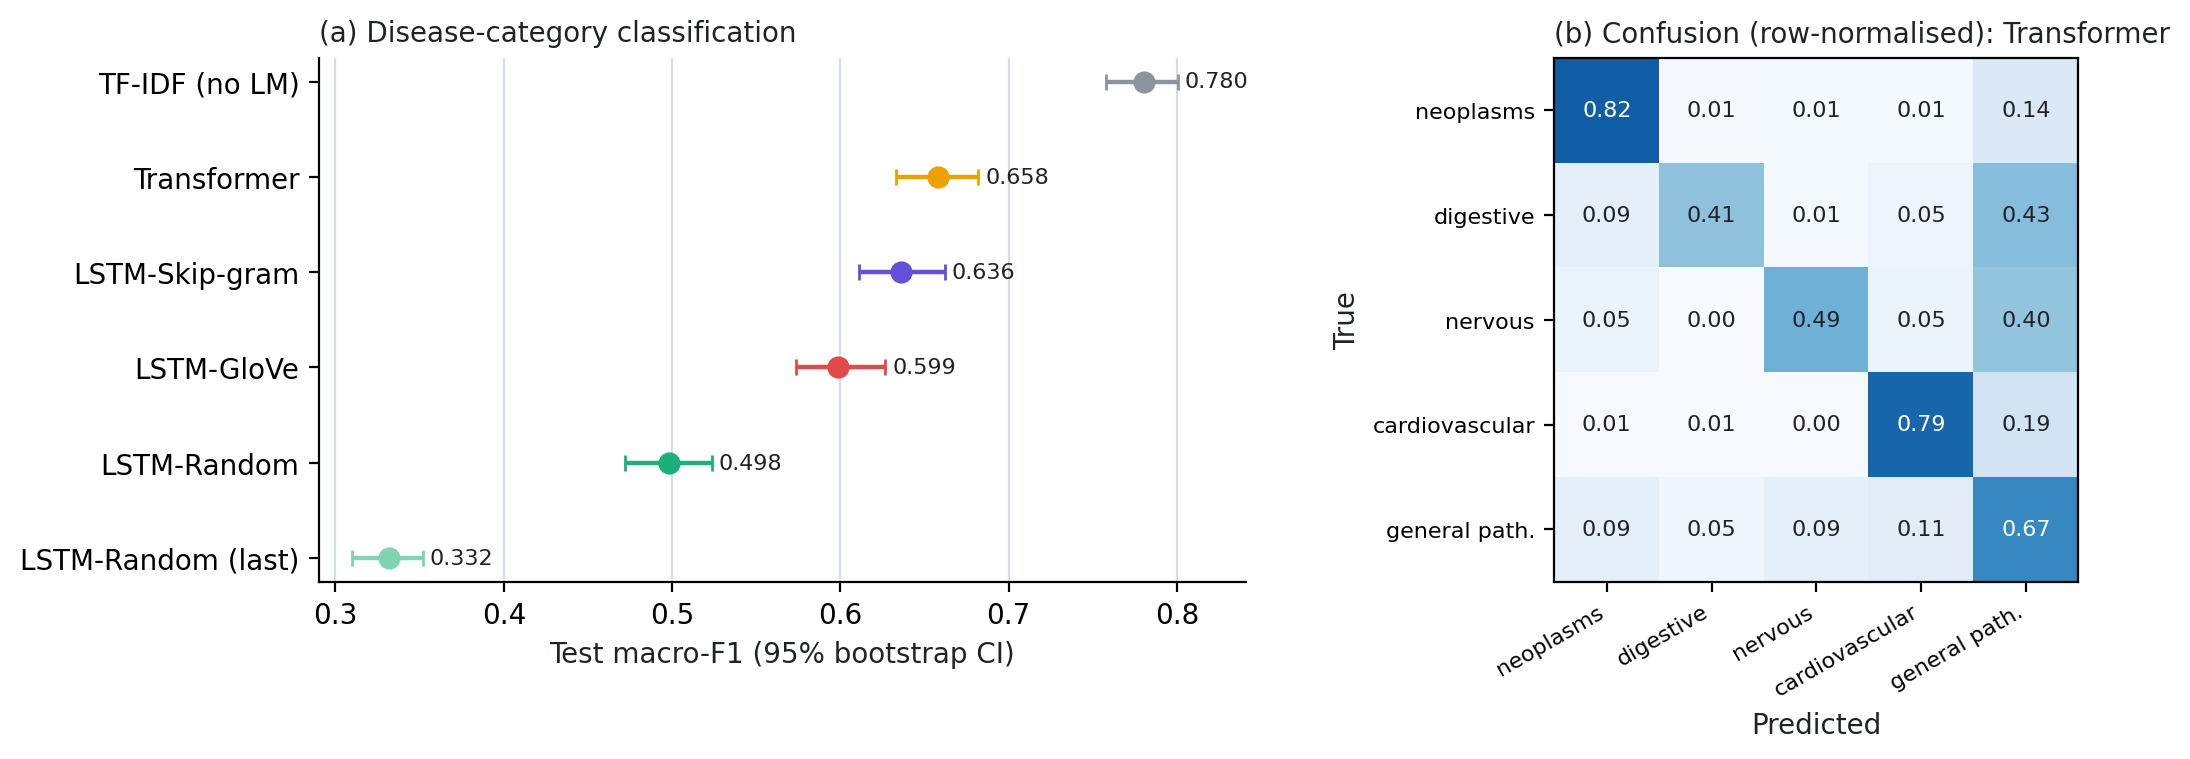

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment

from IPython.display import Markdown, Image, display
display(Markdown(open("results/part3/summary.md").read().split("![Part III]")[0]))
display(Image("results/part3/fig_part3.png"))

## 7. Download the results (optional; they are also in Drive)

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment

import glob, os, zipfile
out = "/content/part3_results.zip"
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for path in glob.glob("results/part3/*"):
        if os.path.isfile(path):
            z.write(path)
from google.colab import files
files.download(out)

/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>